<a href="https://colab.research.google.com/github/surajgade17/Molecular-Fingerprinting-Similarity-Analysis/blob/main/Molecular_Fingerprinting_Similarity_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Molecular Fingerprinting & Similarity Analysis Using RDKit

Independent educational portfolio project. Compare example molecules using Morgan fingerprints, MACCS keys and Tanimoto similarity.

**Caution:** fingerprint similarity is not proof of biological activity or therapeutic equivalence.

## 1. Install dependencies

In [1]:
!pip install -q rdkit pandas numpy matplotlib seaborn reportlab


## 2. Imports and setup

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import AllChem, MACCSkeys, Draw
from IPython.display import display
from google.colab import files

print("RDKit version:", rdBase.rdkitVersion)
OUT = Path("output")
OUT.mkdir(exist_ok=True)


RDKit version: 2026.09.2


## 3. Load the sample dataset

In [3]:
data_path = Path("data/molecule_dataset.csv")
if not data_path.exists():
    uploaded = files.upload()
    data_path = Path(next(iter(uploaded)))
df = pd.read_csv(data_path)
display(df.head())
print("Dataset rows:", len(df))


Saving molecule_dataset.csv to molecule_dataset.csv


,Name,SMILES,Category
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,Analgesic
1,Salicylic acid,O=C(O)c1ccccc1O,Aromatic acid
2,Ibuprofen,CC(C)Cc1ccc(cc1)C(C)C(=O)O,Analgesic
3,Naproxen,COc1ccc2cc(ccc2c1)C(C)C(=O)O,Analgesic
4,Paracetamol,CC(=O)Nc1ccc(O)cc1,Analgesic


Dataset rows: 20


## 4. Validate SMILES

In [4]:
records, invalid = [], []
for _, row in df.iterrows():
    mol = Chem.MolFromSmiles(str(row["SMILES"]))
    if mol is None:
        invalid.append({"Name": row["Name"], "SMILES": row["SMILES"]})
    else:
        records.append({"Name": str(row["Name"]), "SMILES": str(row["SMILES"]), "mol": mol})
if len(records) < 2:
    raise ValueError("At least two valid molecules are required.")
names = [r["Name"] for r in records]
mols = [r["mol"] for r in records]
print("Valid:", len(records), "| Invalid:", len(invalid))


Valid: 19 | Invalid: 1


## 5. Generate Morgan fingerprints and MACCS keys

In [5]:
RADIUS, N_BITS = 2, 2048
morgan = [AllChem.GetMorganFingerprintAsBitVect(m, RADIUS, nBits=N_BITS) for m in mols]
maccs = [MACCSkeys.GenMACCSKeys(m) for m in mols]
print("Fingerprints generated for", len(mols), "molecules")


Fingerprints generated for 19 molecules


## 6. Calculate Tanimoto similarity matrices

In [6]:
def similarity_matrix(fps):
    return np.array([DataStructs.BulkTanimotoSimilarity(fp, fps) for fp in fps])
morgan_matrix = similarity_matrix(morgan)
maccs_matrix = similarity_matrix(maccs)
morgan_df = pd.DataFrame(morgan_matrix, index=names, columns=names)
maccs_df = pd.DataFrame(maccs_matrix, index=names, columns=names)
display(morgan_df.round(3))


,Aspirin,Salicylic acid,Ibuprofen,Naproxen,Paracetamol,Caffeine,Theobromine,Benzene,Toluene,Phenol,Aniline,Benzoic acid,Methyl benzoate,Ethylbenzene,Acetanilide,Benzamide,Lidocaine,Metformin,Captopril
Aspirin,1.000,0.448,0.195,0.205,0.222,0.089,0.085,0.125,0.250,0.250,0.207,0.357,0.344,0.226,0.344,0.290,0.178,0.051,0.100
Salicylic acid,0.448,1.000,0.194,0.175,0.226,0.075,0.071,0.167,0.261,0.381,0.261,0.455,0.321,0.231,0.321,0.360,0.175,0.029,0.089
Ibuprofen,0.195,0.194,1.000,0.421,0.184,0.087,0.083,0.077,0.161,0.161,0.125,0.219,0.222,0.219,0.222,0.206,0.174,0.050,0.167
Naproxen,0.205,0.175,0.421,1.000,0.167,0.080,0.098,0.067,0.143,0.143,0.111,0.194,0.263,0.132,0.200,0.184,0.137,0.045,0.132
Paracetamol,0.222,0.226,0.184,0.167,1.000,0.098,0.093,0.045,0.148,0.292,0.107,0.214,0.258,0.133,0.625,0.200,0.225,0.088,0.085
Caffeine,0.089,0.075,0.087,0.080,0.098,1.000,0.368,0.037,0.091,0.059,0.059,0.083,0.100,0.114,0.100,0.079,0.102,0.024,0.057
Theobromine,0.085,0.071,0.083,0.098,0.093,0.368,1.000,0.034,0.086,0.056,0.056,0.108,0.150,0.079,0.095,0.103,0.077,0.023,0.055
Benzene,0.125,0.167,0.077,0.067,0.045,0.037,0.034,1.000,0.273,0.273,0.273,0.214,0.158,0.214,0.158,0.188,0.067,0.000,0.030
Toluene,0.250,0.261,0.161,0.143,0.148,0.091,0.086,0.273,1.000,0.375,0.375,0.316,0.304,0.389,0.304,0.286,0.176,0.037,0.050
Phenol,0.250,0.381,0.161,0.143,0.292,0.059,0.056,0.273,0.375,1.000,0.375,0.389,0.304,0.316,0.304,0.350,0.143,0.037,0.050


## 7. Plot heatmaps

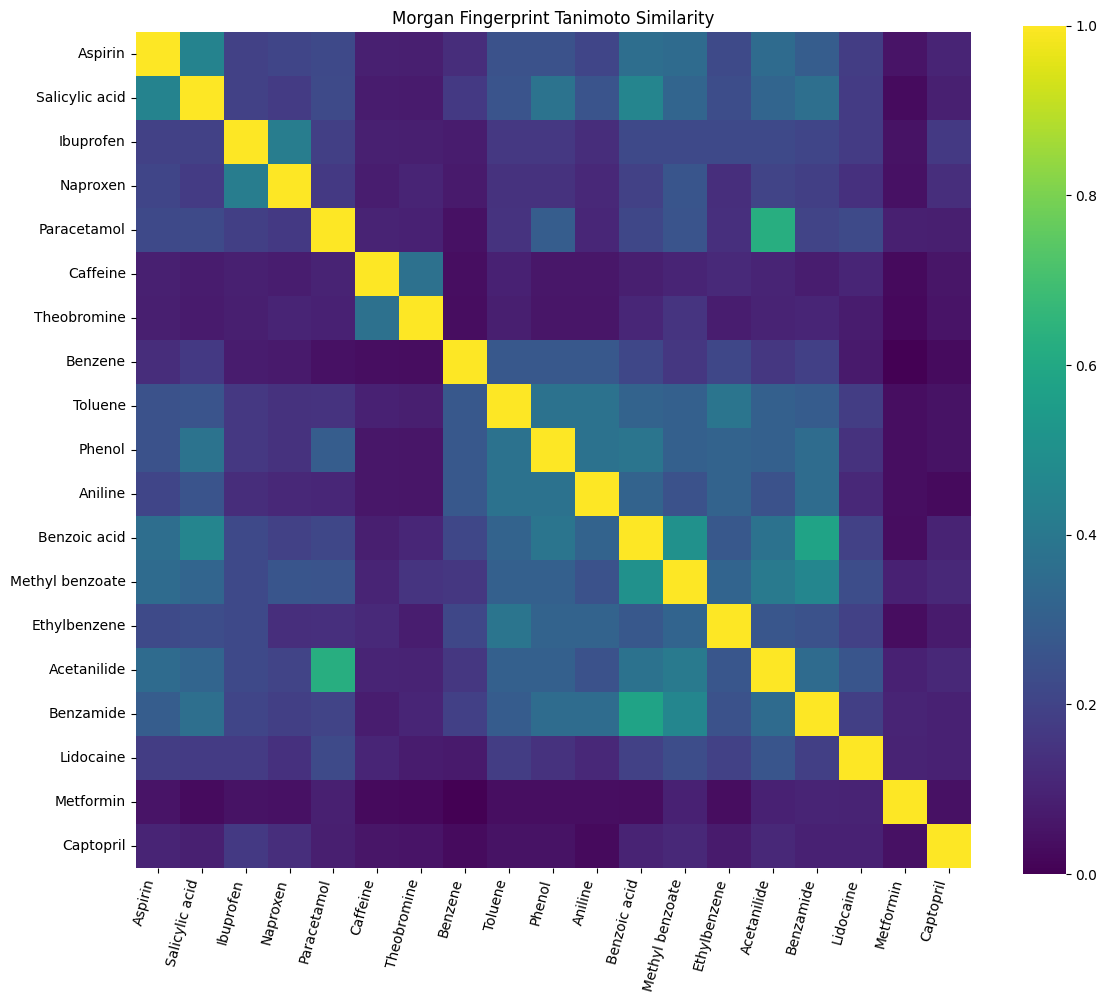

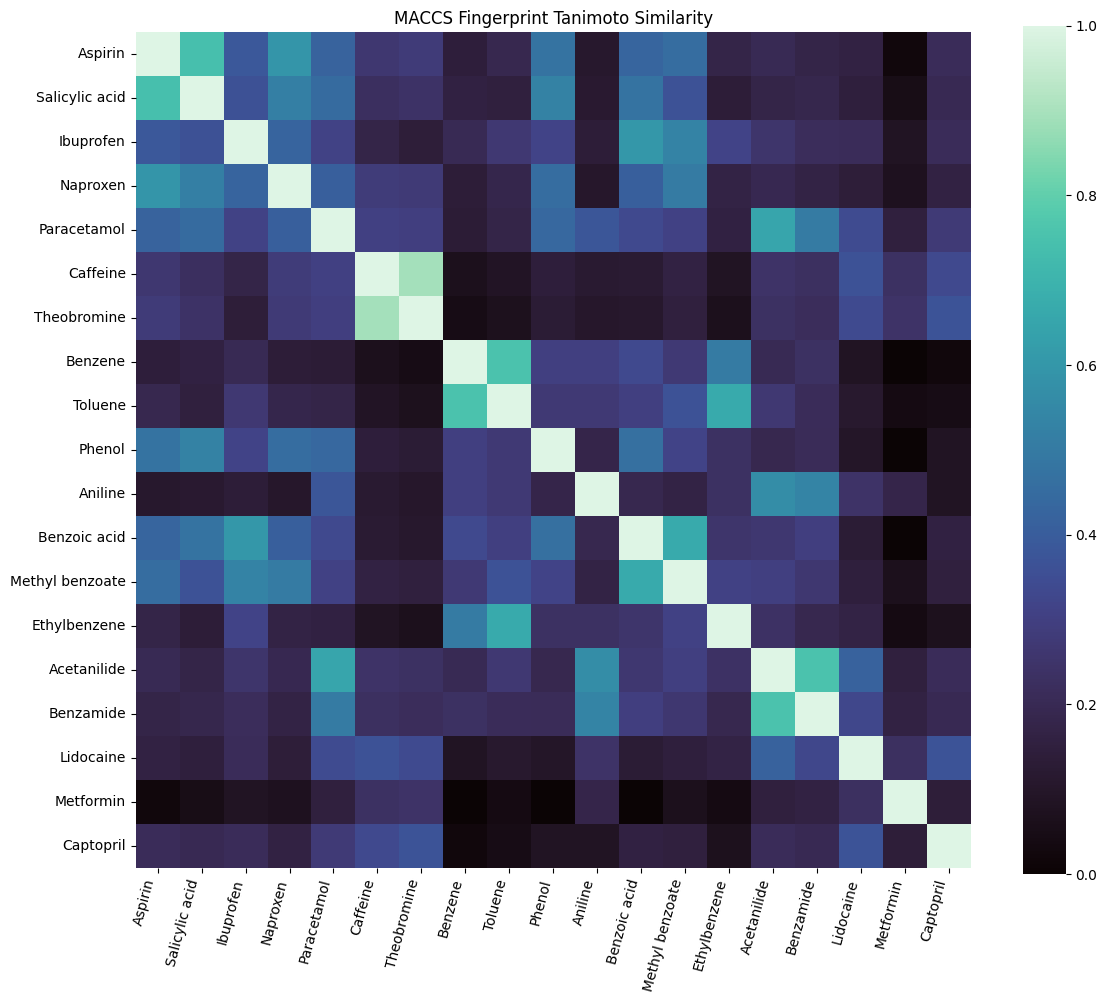

In [7]:
for label, frame, cmap in [("Morgan", morgan_df, "viridis"), ("MACCS", maccs_df, "mako")]:
    plt.figure(figsize=(12, 10))
    sns.heatmap(frame, cmap=cmap, vmin=0, vmax=1, square=True)
    plt.title(f"{label} Fingerprint Tanimoto Similarity")
    plt.xticks(rotation=75, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(OUT / f"{label.lower()}_similarity_heatmap.png", dpi=300)
    plt.show()


## 8. Rank pairwise similarities

In [8]:
pairs = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        pairs.append([names[i], names[j], morgan_matrix[i, j], maccs_matrix[i, j]])
pair_df = pd.DataFrame(pairs, columns=["Molecule_1", "Molecule_2", "Morgan_Tanimoto", "MACCS_Tanimoto"])
pair_df = pair_df.sort_values("Morgan_Tanimoto", ascending=False)
display(pair_df.head(15).round(3))


,Molecule_1,Molecule_2,Morgan_Tanimoto,MACCS_Tanimoto
75,Paracetamol,Acetanilide,0.625,0.652
146,Benzoic acid,Benzamide,0.579,0.294
143,Benzoic acid,Methyl benzoate,0.500,0.667
152,Methyl benzoate,Benzamide,0.458,0.263
27,Salicylic acid,Benzoic acid,0.455,0.474
0,Aspirin,Salicylic acid,0.448,0.739
35,Ibuprofen,Naproxen,0.421,0.423
151,Methyl benzoate,Acetanilide,0.407,0.300
120,Toluene,Ethylbenzene,0.389,0.667
127,Phenol,Benzoic acid,0.389,0.462


## 9. Draw molecule structures

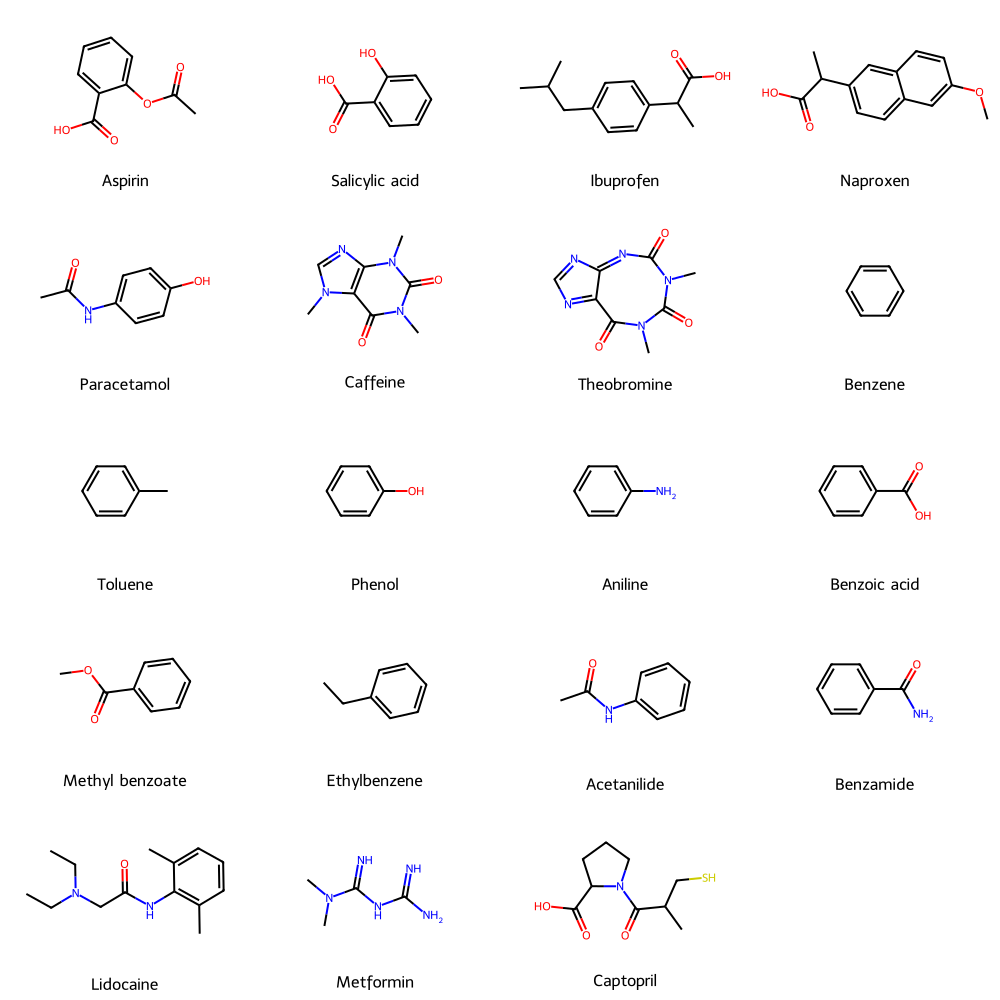

In [9]:
img = Draw.MolsToGridImage(mols[:20], molsPerRow=4, subImgSize=(250, 200), legends=names[:20], useSVG=False)
display(img)
img.save(str(OUT / "molecule_structure_grid.png"))


## 10. Export CSV files

In [10]:
morgan_df.to_csv(OUT / "morgan_similarity_matrix.csv")
maccs_df.to_csv(OUT / "maccs_similarity_matrix.csv")
pair_df.to_csv(OUT / "pairwise_similarity_scores.csv", index=False)
pd.DataFrame({
    "Name": names,
    "Canonical_SMILES": [Chem.MolToSmiles(m) for m in mols],
    "Morgan_Bits": [N_BITS] * len(mols),
    "Morgan_On_Bits": [fp.GetNumOnBits() for fp in morgan],
    "MACCS_On_Bits": [fp.GetNumOnBits() for fp in maccs]
}).to_csv(OUT / "fingerprint_summary.csv", index=False)
if invalid:
    pd.DataFrame(invalid).to_csv(OUT / "invalid_smiles_rows.csv", index=False)
print("CSV outputs saved.")


CSV outputs saved.


## 11. Generate a PDF report

In [11]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image

styles = getSampleStyleSheet()
pdf_path = OUT / "Molecular_Similarity_Analysis_Report.pdf"
doc = SimpleDocTemplate(str(pdf_path), pagesize=A4)
story = [
    Paragraph("Molecular Fingerprinting & Similarity Analysis", styles["Title"]),
    Spacer(1, 10),
    Paragraph(f"Valid molecules analysed: {len(records)}; invalid SMILES skipped: {len(invalid)}.", styles["BodyText"]),
    Spacer(1, 10),
    Paragraph("Top 10 pairs by Morgan Tanimoto similarity", styles["Heading2"])
]
table_data = [["Molecule 1", "Molecule 2", "Morgan Tanimoto"]]
for _, r in pair_df.head(10).iterrows():
    table_data.append([r.Molecule_1, r.Molecule_2, f"{r.Morgan_Tanimoto:.3f}"])
table = Table(table_data, repeatRows=1, colWidths=[145, 145, 100])
table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#263B5A")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("GRID", (0,0), (-1,-1), 0.4, colors.grey)
]))
story += [table, Spacer(1, 12), Image(str(OUT / "morgan_similarity_heatmap.png"), width=460, height=380),
          Spacer(1, 8), Paragraph("Fingerprint similarity is not evidence of biological activity, safety, potency or therapeutic equivalence.", styles["BodyText"])]
doc.build(story)
print("PDF saved:", pdf_path)


PDF saved: output/Molecular_Similarity_Analysis_Report.pdf


## 12. Download all generated outputs

In [12]:
import shutil
zip_path = shutil.make_archive("Molecular_Similarity_Analysis_Outputs", "zip", OUT)
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Interpretation and limitations

- Tanimoto similarity ranges from 0 to 1 for these binary fingerprints.
- A score of 1 indicates identical fingerprint bit vectors.
- Rankings can change with fingerprint type and parameters.
- Similarity does not establish biological activity, safety, potency, binding affinity or clinical usefulness.